# 03 · Exploratory data analysis

We explore the data with one question in mind: **what, known before a fight, relates to who wins?**

A trick used throughout: to study an attribute like reach without the red-corner bias, use the **long table** (each fight seen from both sides).
Every fight contributes one win and one loss, so the baseline is exactly 50%.

In [1]:
import os, sys
from pathlib import Path
# Run from the project root no matter where Jupyter was started.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
from ufc.viz import use_style, RED_CORNER, BLUE_CORNER, METHOD_COLORS, SERIES, INK_2, NEUTRAL
from ufc.features import add_history
use_style()
fights = pd.read_parquet("data/processed/fights.parquet")
ff = add_history(pd.read_parquet("data/processed/fighter_fights.parquet"))
decided = fights[fights.red_win.notna()]
fights["year"] = fights.date.dt.year

## 1 · The target: red corner bias

All decided fights: red wins 63.9%  <- inflated by the pre-2010 artifact
Since 2010-03-21:   red wins 57.7%  <- the real baseline to beat


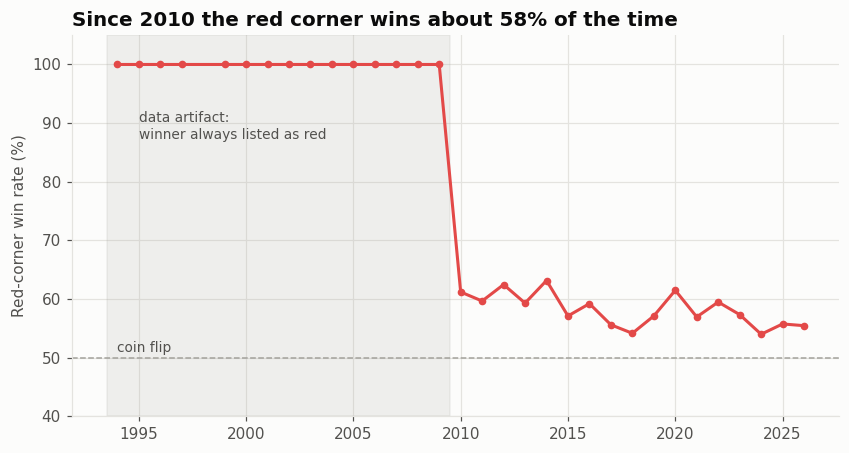

In [2]:
reliable = decided[decided.corners_reliable]
print(f"All decided fights: red wins {decided.red_win.mean():.1%}  <- inflated by the pre-2010 artifact")
print(f"Since 2010-03-21:   red wins {reliable.red_win.mean():.1%}  <- the real baseline to beat")
by_year = decided.assign(year=decided.date.dt.year).groupby("year").agg(red_rate=("red_win","mean"), n=("red_win","size"))
by_year = by_year[by_year.n >= 30]

fig, ax = plt.subplots()
ax.plot(by_year.index, by_year.red_rate * 100, color=RED_CORNER, marker="o", markersize=4)
ax.axhline(50, color=NEUTRAL, lw=1, ls="--"); ax.text(by_year.index.min(), 51, "coin flip", color=INK_2, fontsize=9)
ax.axvspan(by_year.index.min() - 0.5, 2009.5, color=NEUTRAL, alpha=0.15)
ax.text(1995, 92, "data artifact:\nwinner always listed as red", color=INK_2, fontsize=9, va="top")
ax.set_ylim(40, 105); ax.set_ylabel("Red-corner win rate (%)")
ax.set_title("Since 2010 the red corner wins about 58% of the time")
plt.show()

The shaded years aren't real: before March 2010, ufcstats puts the winner in the red slot (see notebook 01). From 2010 on, red (usually the favorite) wins about 58%, drifting down over time (about 55% in 2024–2026).

## 2 · How much data per year and division

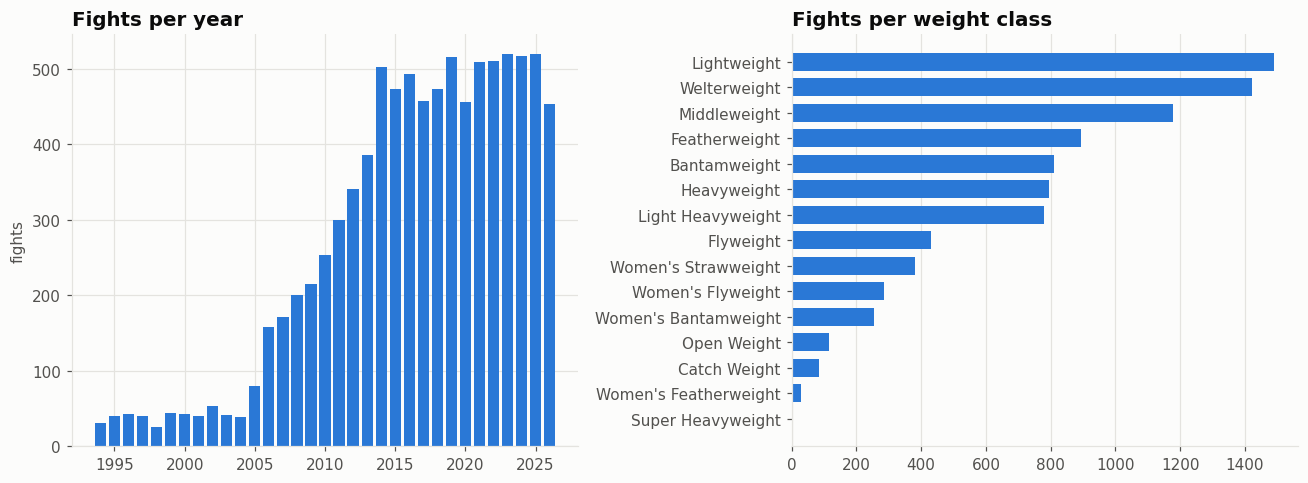

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
per_year = fights.groupby("year").size()
axes[0].bar(per_year.index, per_year.values, color=SERIES[0], width=0.8)
axes[0].set_title("Fights per year"); axes[0].set_ylabel("fights")
wc = fights.weight_class.value_counts().sort_values()
axes[1].barh(wc.index, wc.values, color=SERIES[0], height=0.7)
axes[1].set_title("Fights per weight class"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Over half the fights are from 2014 onward. The modern era dominates, which is good, because that's what we'll predict.

## 3 · How fights end, by division

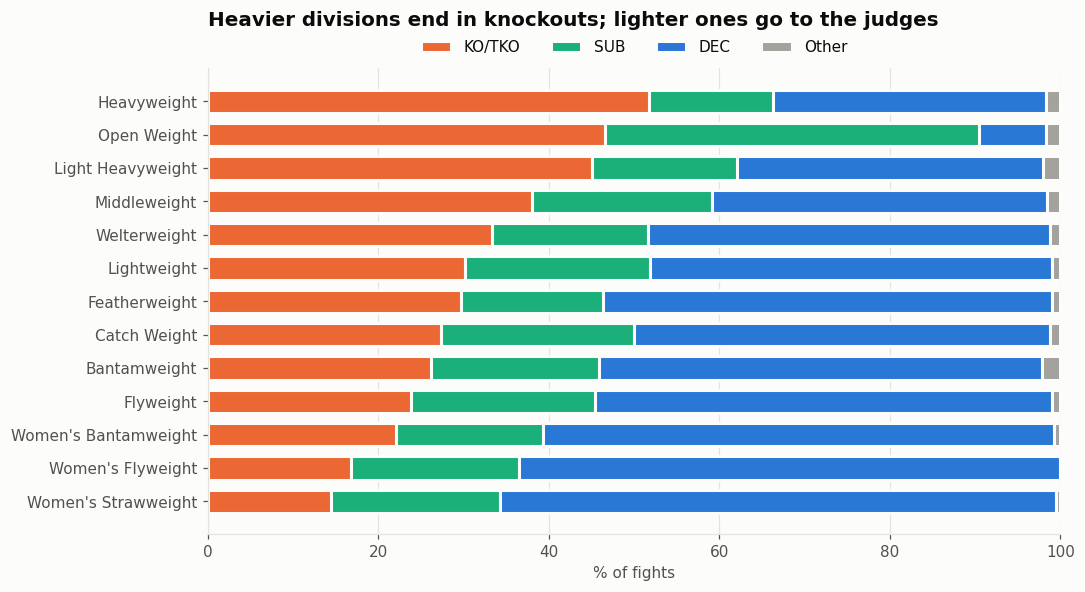

In [4]:
order = ["KO/TKO", "SUB", "DEC", "Other"]
share = (pd.crosstab(fights.weight_class, fights.method_group, normalize="index")[order] * 100)
share = share.loc[fights.weight_class.value_counts().loc[lambda s: s >= 60].index].sort_values("KO/TKO")

fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(share))
for m in order:
    ax.barh(share.index, share[m], left=left, color=METHOD_COLORS[m], label=m, height=0.7,
            edgecolor="#fcfcfb", linewidth=2)
    left += share[m].values
ax.set_xlim(0, 100); ax.set_xlabel("% of fights"); ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Heavier divisions end in knockouts; lighter ones go to the judges", pad=28)
plt.show()

## 4 · When do finishes happen?

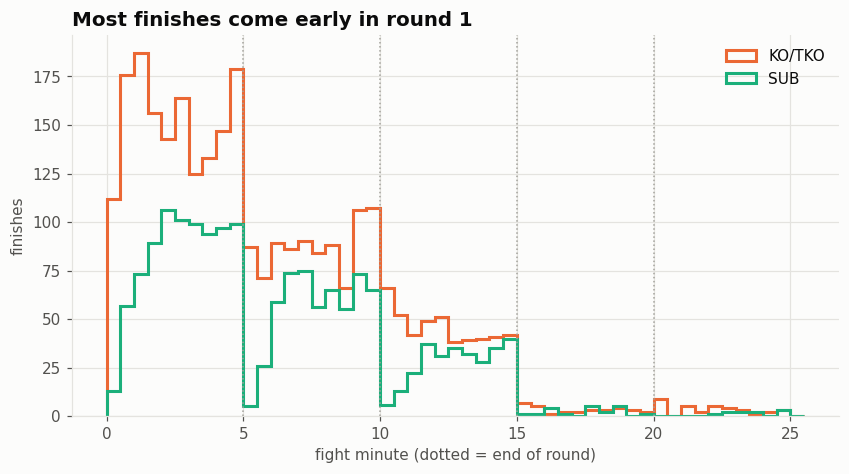

In [5]:
fin = fights[fights.method_group.isin(["KO/TKO","SUB"]) & (fights.total_rounds > 1)]
fig, ax = plt.subplots()
for m in ["KO/TKO", "SUB"]:
    ax.hist(fin.loc[fin.method_group == m, "fight_seconds"] / 60, bins=np.arange(0, 26, 0.5),
            histtype="step", lw=2, color=METHOD_COLORS[m], label=m)
for r in range(1, 5): ax.axvline(5 * r, color=NEUTRAL, lw=1, ls=":")
ax.set_xlabel("fight minute (dotted = end of round)"); ax.set_ylabel("finishes"); ax.legend()
ax.set_title("Most finishes come early in round 1")
plt.show()

## 5 · Physical edges (symmetric view)
For each fighter in each fight: their advantage over the opponent, and whether they won.

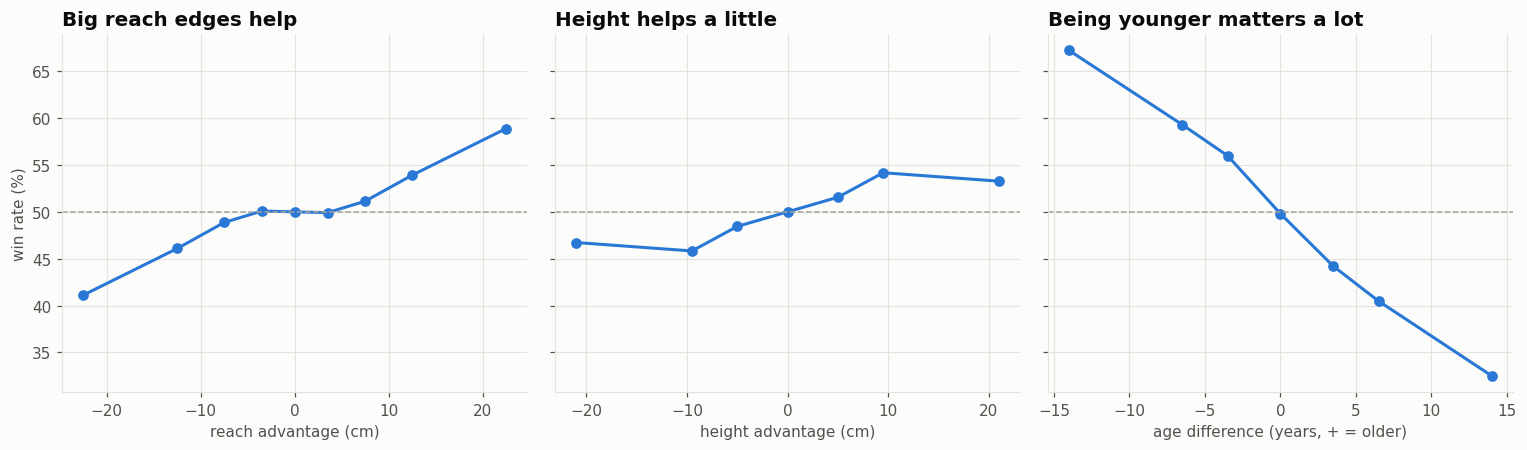

In [6]:
wl = ff[ff.result.isin(["W", "L"])].copy()
wl["won"] = (wl.result == "W").astype(int)
opp = wl.set_index(["fight_id","fighter"])[["reach","height","age_at_fight"]]
wl = wl.merge(wl[["fight_id","fighter","reach","height","age_at_fight"]]
                .rename(columns={"fighter":"opponent","reach":"o_reach","height":"o_height","age_at_fight":"o_age"}),
              on=["fight_id","opponent"])
wl["reach_adv"] = wl.reach - wl.o_reach
wl["height_adv"] = wl.height - wl.o_height
wl["age_adv"] = wl.age_at_fight - wl.o_age

def binned_rate(col, bins):
    b = pd.cut(wl[col], bins)
    g = wl.groupby(b, observed=True).won.agg(["mean","size"])
    return g[g["size"] >= 50]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
specs = [("reach_adv", [-30,-15,-10,-5,-2,2,5,10,15,30], "reach advantage (cm)"),
         ("height_adv", [-30,-12,-7,-3,3,7,12,30], "height advantage (cm)"),
         ("age_adv", [-20,-8,-5,-2,2,5,8,20], "age difference (years, + = older)")]
for ax, (col, bins, label) in zip(axes, specs):
    g = binned_rate(col, bins)
    mids = [i.mid for i in g.index]
    ax.plot(mids, g["mean"] * 100, marker="o", color=SERIES[0])
    ax.axhline(50, color=NEUTRAL, lw=1, ls="--"); ax.set_xlabel(label)
axes[0].set_ylabel("win rate (%)")
axes[0].set_title("Big reach edges help"); axes[1].set_title("Height helps a little"); axes[2].set_title("Being younger matters a lot")
plt.tight_layout(); plt.show()

Age is by far the strongest physical signal. A fighter 8+ years older than their opponent wins only about a third of the time. A big reach edge (15+ cm) is worth about 59%. Height helps only a little, since height and reach overlap and weight classes keep sizes similar.

## 6 · Stance matchups

In [7]:
st = wl.merge(wl[["fight_id","fighter","stance"]].rename(columns={"fighter":"opponent","stance":"o_stance"}),
              on=["fight_id","opponent"])
main = ["Orthodox","Southpaw","Switch"]
st = st[st.stance.isin(main) & st.o_stance.isin(main)]
tab = st.pivot_table(index="stance", columns="o_stance", values="won", aggfunc="mean").loc[main, main] * 100
n = st.pivot_table(index="stance", columns="o_stance", values="won", aggfunc="size").loc[main, main]
print("Win rate (%) of the ROW stance against the COLUMN stance; n fights below")
display(tab.round(1)); display(n)

Win rate (%) of the ROW stance against the COLUMN stance; n fights below


o_stance,Orthodox,Southpaw,Switch
stance,,,
Orthodox,50.0,46.8,47.8
Southpaw,53.2,50.0,45.6
Switch,52.2,54.4,50.0


o_stance,Orthodox,Southpaw,Switch
stance,,,
Orthodox,9668,2452,715
Southpaw,2452,694,193
Switch,715,193,106


Southpaws beat orthodox fighters about 52–53% of the time. That's a small edge, but it's consistent and well known in combat sports (orthodox fighters rarely train against lefties).

## 7 · Experience

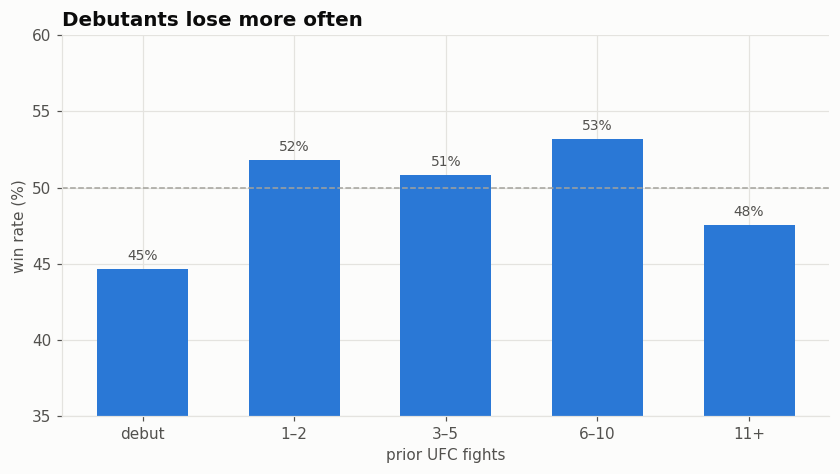

In [8]:
bucket = pd.cut(wl.n_fights, [-1, 0, 2, 5, 10, 50], labels=["debut","1–2","3–5","6–10","11+"])
exp = wl.groupby(bucket, observed=True).won.agg(["mean","size"])
fig, ax = plt.subplots()
ax.bar(exp.index.astype(str), exp["mean"] * 100, color=SERIES[0], width=0.6)
ax.axhline(50, color=NEUTRAL, lw=1, ls="--"); ax.set_ylim(35, 60)
for i, (v, nn) in enumerate(zip(exp["mean"], exp["size"])):
    ax.text(i, v * 100 + 0.6, f"{v:.0%}", ha="center", color=INK_2, fontsize=9)
ax.set_xlabel("prior UFC fights"); ax.set_ylabel("win rate (%)")
ax.set_title("Debutants lose more often")
plt.show()

Debutants win only about 45%. The win rate climbs with experience, then dips for 11+ fight veterans, who are often older and facing younger opponents. Experience and age interact, a hint that tree models may help later.

## 8 · Which pre-fight features relate to winning?
Correlation of each **red − blue difference** (computed from prior fights only) with `red_win`, using fights since 2010‑03 only. It's a rough, one-at-a-time view; the models in notebook 04 do it properly.

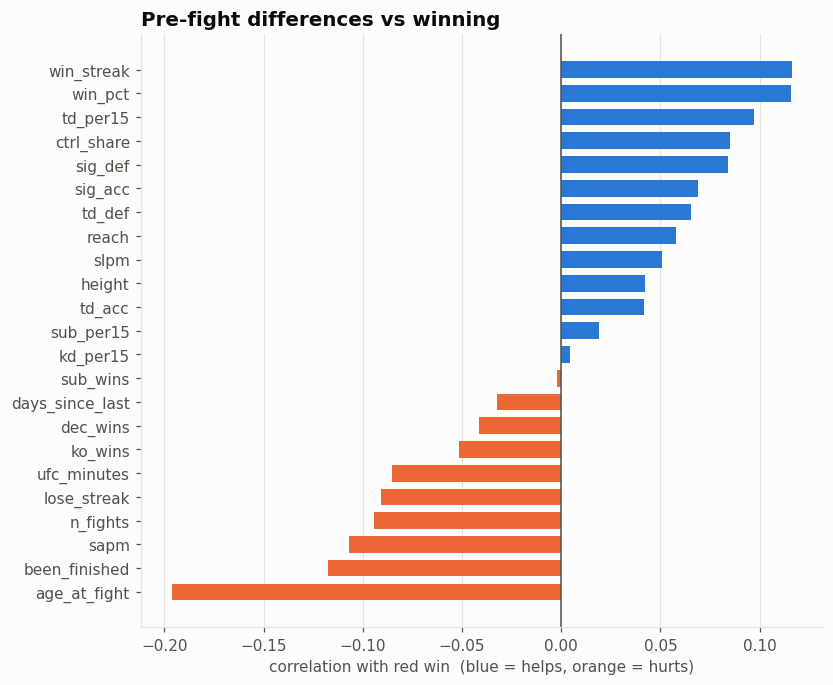

In [9]:
from ufc.features import build_model_table, MIN_FEATURES, HIST_FEATURES
t = build_model_table(fights, ff)
diffs = [f + "_diff" for f in MIN_FEATURES + HIST_FEATURES]
corr = t[diffs].corrwith(t.red_win).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh([c.replace("_diff","") for c in corr.index], corr.values,
        color=[SERIES[0] if v > 0 else SERIES[1] for v in corr.values], height=0.7)
ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("correlation with red win  (blue = helps, orange = hurts)")
ax.set_title("Pre-fight differences vs winning")
plt.show()

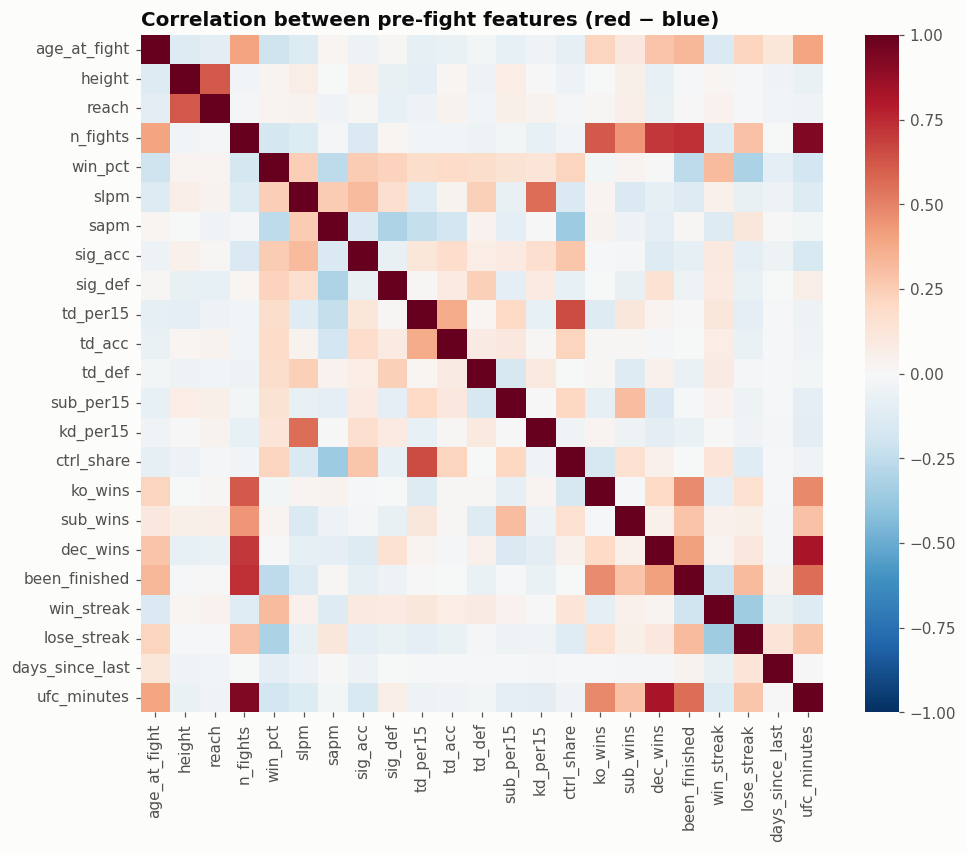

In [10]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(t[diffs].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=[d.replace("_diff","") for d in diffs], yticklabels=[d.replace("_diff","") for d in diffs])
ax.set_title("Correlation between pre-fight features (red − blue)")
plt.show()

**Things to notice in the heatmap:** `n_fights`, `ufc_minutes`, and the win-type counts (`ko_wins`, `dec_wins`) are all strongly correlated, because they mostly measure experience. Linear models handle that poorly (unstable coefficients). Good candidates later for regularization or for consolidating into one experience feature.

## EDA takeaways
1. **Red wins about 58% since 2010.** The 65.5% headline number is inflated by a data artifact.
2. **Age at fight** is the strongest physical signal. Reach matters at big gaps, height only a little.
3. **Southpaw** has a small, steady edge over orthodox (about 53%).
4. **Debutants** lose more. Experience helps until age catches up.
5. Career-to-date style stats (strikes absorbed, defense, takedown defense) relate to winning, but they're noisy for fighters with few fights. → `04_baseline_features.ipynb`